# 70 - TF-IDF + K-Means

Agrupa descricoes fiscais usando TF-IDF e K-Means, com os mesmos controles de amostra e avaliacao dos notebooks 71 a 76. Vetores zerados sao um diagnostico da representacao; K-Means nao classifica itens como ruido. A definicao de categorias e a avaliacao da reserva continuam dependendo de revisao humana.


In [1]:
from matplotlib.colors import ListedColormap
import json
import logging
from pathlib import Path
from dataclasses import asdict
from datetime import datetime, timezone
from hashlib import sha256
from itertools import product
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn import config_context
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score


from nofis_classifier.schema import DESCRIPTION_NORMALIZED, FREQUENCY
from nofis_classifier.tfidf import TfidfExperimentConfig
from nofis_classifier.clustering import (
    load_local_model, inspect_documents, build_cluster_review,
    save_review_once, predict_categories,
)

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("notebook70")
pd.set_option("display.max_colwidth", 160)


## Configuracoes e comparabilidade

Controles comuns aos notebooks 70 a 76:

- Base completa `2025_NCMs_filtrados_semstopwords`, periodo 202501-202512.
- Ate 20.000 descricoes unicas para agrupamento, amostradas com semente 42 e ordenadas por descricao normalizada. Frequencia nao pondera o ajuste.
- Silhouette cosseno sobre uma amostra base fixa de ate 20.000 linhas, com semente 42. Ruido do algoritmo e excluido depois da amostragem; a quantidade efetivamente avaliada e registrada.
- Ranking exige silhouette definida e de 10 a 1.000 clusters efetivamente formados, sem contar ruido. Pesos: 0,75 para silhouette reescalada e 0,25 para cobertura do algoritmo.
- t-SNE 2D e 3D: mesmos ate 5.000 itens, semente 42, TruncatedSVD de ate 50 componentes, perplexidade 30, 1.000 iteracoes, init PCA (quando ha dimensoes suficientes), learning_rate auto e Barnes-Hut. As projecoes de representacoes diferentes sao exploratorias, nao um espaco comum de distancias.
- `comparison` em `run.json` registra os controles e o hash das descricoes/frequencias usadas no agrupamento.

TF-IDF: os mesmos 10 analyzers dos experimentos de texto, cruzados com `MIN_DF_VALUES = [1, 2, 5, 10]`, max_features 100.000, max_df 1.0, sublinear_tf True, norm l2 e dtype float64. Os vetores zerados sao registrados como diagnostico da representacao, separados do ruido do algoritmo.

K-Means: k 20/50/100/200, semente 42, n_init 10, max_iter 300, algoritmo lloyd. O agrupamento usa as mesmas 20.000 descricoes dos outros notebooks. As 300 descricoes para validacao humana sao retiradas do complemento dessa amostra, antes da vetorizacao, e nunca participam do ajuste ou ranking. Quando a base e menor, e necessario preservar espaco para a reserva. K-Means atribui todos os itens, portanto sua cobertura e 1 e seu ruido e 0.

Grade atual: 40 representacoes TF-IDF x 4 valores de k = 160 ajustes.


In [2]:
RUN_ID = None  # Opcional: informe um identificador unico para esta execucao.
DATASET_NAME = "2025_NCMs_filtrados_semstopwords"
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Nao encontrei a raiz do repositorio com data/processed/.")
DATASET_DIR = PROJECT_ROOT / "data" / "processed" / DATASET_NAME
DATASET_FILES = sorted(DATASET_DIR.glob("*.parquet"))
if not DATASET_FILES:
    raise FileNotFoundError(f"Nenhum Parquet encontrado para {DATASET_NAME}: {DATASET_DIR}")
if len(DATASET_FILES) > 1:
    raise ValueError(
        f"Mais de um Parquet encontrado em {DATASET_DIR}; selecione o arquivo/periodo explicitamente: "
        f"{[path.name for path in DATASET_FILES]}"
    )
DATASET_PATH = DATASET_FILES[0]
if not DATASET_PATH.stem.startswith(f"{DATASET_NAME}-"):
    raise ValueError(f"O nome do arquivo deve comecar com '{DATASET_NAME}-': {DATASET_PATH.name}")
PERIOD_LABEL = DATASET_PATH.stem[len(DATASET_NAME) + 1:]

MAX_DESCRIPTIONS = 20_000
CONSIDER_FREQUENCY_IN_CLUSTERING = False
VALIDATION_COUNT = 300
SPLIT_SEED = 42
REPRESENTATIONS = [
    ('char_wb', (2, 4), [100_000]),
    ('char_wb', (2, 10), [100_000]),
    ('char_wb', (3, 5), [100_000]),
    ('char_wb', (3, 10), [100_000]),
    ('char_wb', (4, 8), [100_000]),
    ('char_wb', (4, 10), [100_000]),
    ('char_wb', (5, 10), [100_000]),
    ('word', (1, 3), [100_000]),
    ('word', (1, 5), [100_000]),
    ('word', (2, 5), [100_000]),
]
MIN_DF_VALUES = [1, 2, 5, 10]
MAX_DF_VALUES = [1.0]
K_VALUES = [20, 50, 100, 200]
SEEDS = [42]
N_INIT = 10
MAX_ITER = 300
SILHOUETTE_SAMPLE_SIZE = 20_000
METRIC_SAMPLE_SIZE = SILHOUETTE_SAMPLE_SIZE
PAIRWISE_WORKING_MEMORY_MIB = 64

MAX_CLUSTERS_FOR_RANKING = 1000
MIN_CLUSTER_FOR_RANKING = 10
SILHOUETTE_WEIGHT = 0.75
NOISE_WEIGHT = 0.25

TOP_COMBINATIONS = 3
TSNE_MAX_POINTS = 5_000
TSNE_SVD_COMPONENTS = 50
TSNE_PERPLEXITY = 30
TSNE_MAX_ITER = 1_000
TSNE_RANDOM_STATE = 42

REPORT_ROOT = PROJECT_ROOT / "reports/tfidf_kmeans"
MODEL_ROOT = PROJECT_ROOT / "models/tfidf_kmeans"


METRIC_RANDOM_STATE = 42

TSNE_3D_N_COMPONENTS = 3


In [3]:
configs = [
    TfidfExperimentConfig(
        name=f"{analyzer}_{ngrams[0]}_{ngrams[1]}_min{min_df}_maxdf{max_df:g}_features{max_features}",
        analyzer=analyzer, ngram_range=ngrams, min_df=min_df,
        max_df=max_df, max_features=max_features,
    )
    for analyzer, ngrams, feature_limits in REPRESENTATIONS
    for min_df, max_df, max_features in product(MIN_DF_VALUES, MAX_DF_VALUES, feature_limits)
]
experiment_matrix = pd.DataFrame([
    {**asdict(config), "k": k, "seed": seed, "n_init": N_INIT}
    for config, k, seed in product(configs, K_VALUES, SEEDS)
])
display(experiment_matrix)
logger.info("Grade planejada: %d ajustes", len(experiment_matrix))


,name,analyzer,ngram_range,min_df,max_features,max_df,sublinear_tf,norm,k,seed,n_init
0,char_wb_2_4_min1_maxdf1_features100000,char_wb,"(2, 4)",1,100000,1.0,True,l2,20,42,10
1,char_wb_2_4_min1_maxdf1_features100000,char_wb,"(2, 4)",1,100000,1.0,True,l2,50,42,10
2,char_wb_2_4_min1_maxdf1_features100000,char_wb,"(2, 4)",1,100000,1.0,True,l2,100,42,10
3,char_wb_2_4_min1_maxdf1_features100000,char_wb,"(2, 4)",1,100000,1.0,True,l2,200,42,10
4,char_wb_2_4_min2_maxdf1_features100000,char_wb,"(2, 4)",2,100000,1.0,True,l2,20,42,10
...,...,...,...,...,...,...,...,...,...,...,...
155,word_2_5_min5_maxdf1_features100000,word,"(2, 5)",5,100000,1.0,True,l2,200,42,10
156,word_2_5_min10_maxdf1_features100000,word,"(2, 5)",10,100000,1.0,True,l2,20,42,10
157,word_2_5_min10_maxdf1_features100000,word,"(2, 5)",10,100000,1.0,True,l2,50,42,10
158,word_2_5_min10_maxdf1_features100000,word,"(2, 5)",10,100000,1.0,True,l2,100,42,10


2026-10-24 15:33:32,261 INFO Grade planejada: 160 ajustes


In [4]:
def compute_tsne_projection(features, max_points, perplexity, max_iter, random_state, n_components=2):
    """Usa a mesma amostra, SVD e parametros t-SNE em todas as representacoes."""
    point_count = features.shape[0]
    sample_count = min(point_count, max_points)
    if sample_count < 3 or n_components not in (2, 3):
        raise ValueError("t-SNE exige pelo menos tres itens e n_components 2 ou 3.")
    rng = np.random.default_rng(random_state)
    indices = np.sort(rng.choice(point_count, size=sample_count, replace=False))
    sampled = features[indices]
    dimensions = min(TSNE_SVD_COMPONENTS, sampled.shape[1] - 1, sample_count - 1)
    if dimensions >= 1:
        reduced = TruncatedSVD(n_components=dimensions, random_state=random_state).fit_transform(sampled)
    else:
        reduced = sampled.toarray() if hasattr(sampled, "toarray") else np.asarray(sampled)
        dimensions = reduced.shape[1]
    coordinates = TSNE(
        n_components=n_components,
        perplexity=min(float(perplexity), (sample_count - 1) / 3),
        init="pca" if dimensions >= n_components else "random",
        learning_rate="auto", max_iter=max_iter, random_state=random_state,
        method="barnes_hut",
    ).fit_transform(reduced)
    return indices, coordinates, dimensions

def save_tsne_plot(coordinates, labels, run_id, output_path):
    """Salva um PNG t-SNE colorido pelos clusters, com o ru?do em cinza."""
    labels = np.asarray(labels)
    noise_mask = labels == -1
    cluster_ids = np.unique(labels[~noise_mask])
    if cluster_ids.size:
        palette = plt.get_cmap("tab20").colors
        cluster_cmap = ListedColormap([
            palette[index % len(palette)] for index in range(len(cluster_ids))
        ])
        cluster_codes = np.searchsorted(cluster_ids, labels[~noise_mask])
    else:
        cluster_cmap = None
        cluster_codes = np.empty(0, dtype=int)

    figure, axis = plt.subplots(figsize=(11, 8), constrained_layout=True)
    if noise_mask.any():
        axis.scatter(
            coordinates[noise_mask, 0], coordinates[noise_mask, 1],
            c="#b8b8b8", s=8, alpha=0.3, linewidths=0,
        )
    if cluster_ids.size:
        axis.scatter(
            coordinates[~noise_mask, 0], coordinates[~noise_mask, 1],
            c=cluster_codes, cmap=cluster_cmap, vmin=-0.5,
            vmax=len(cluster_ids) - 0.5, s=9, alpha=0.75, linewidths=0,
        )
    axis.set_title(
        f"t-SNE: {run_id}\n{len(cluster_ids)} clusters; "
        f"{int(noise_mask.sum()):,} descri??es como ru?do"
    )
    axis.set_xlabel("t-SNE 1")
    axis.set_ylabel("t-SNE 2")
    axis.text(
        0.01, 0.01,
        "Ru?do em cinza; as cores se repetem a cada 20 clusters.",
        transform=axis.transAxes, fontsize=8, color="#555555",
    )
    figure.savefig(output_path, dpi=160)
    plt.close(figure)

def save_tsne_3d_html(coordinates, labels, run_id, output_path):
    """Salva uma visualiza??o t-SNE 3D interativa e autocontida em HTML."""
    points = [
        {"x": float(x), "y": float(y), "z": float(z), "label": int(label)}
        for (x, y, z), label in zip(coordinates, labels)
    ]
    data_json = json.dumps(points, separators=(",", ":"))
    title = str(run_id).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    page = r"""<!doctype html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>t-SNE 3D: __TITLE__</title>
<style>
html, body { margin: 0; height: 100%; background: #f7f8fa; color: #202124; font: 14px system-ui, sans-serif; }
main { display: flex; flex-direction: column; height: 100%; }
header { padding: 12px 18px; background: white; border-bottom: 1px solid #ddd; }
h1 { margin: 0 0 4px; font-size: 17px; }
p { margin: 0; color: #555; }
canvas { display: block; width: 100%; flex: 1; min-height: 300px; cursor: grab; }
canvas:active { cursor: grabbing; }
</style>
</head>
<body>
<main>
<header><h1>Proje??o t-SNE 3D: __TITLE__</h1><p>Arraste para girar; use a roda do mouse para aproximar. Ru?do em cinza.</p></header>
<canvas id="plot"></canvas>
</main>
<script>
const points = __POINTS__;
const canvas = document.getElementById("plot");
const ctx = canvas.getContext("2d");
let yaw = 0.65, pitch = -0.35, zoom = 1, dragging = false, lastX = 0, lastY = 0;
const colors = ["#3366cc", "#dc3912", "#ff9900", "#109618", "#990099", "#0099c6", "#dd4477", "#66aa00", "#b82e2e", "#316395", "#994499", "#22aa99", "#aaaa11", "#6633cc", "#e67300", "#8b0707", "#651067", "#329262", "#5574a6", "#3b3eac"];
const bounds = ["x", "y", "z"].map(key => {
  const values = points.map(point => point[key]);
  const low = Math.min(...values), high = Math.max(...values);
  return { low, span: Math.max(high - low, 1e-9) };
});
function resize() {
  const ratio = window.devicePixelRatio || 1;
  canvas.width = Math.max(1, Math.floor(canvas.clientWidth * ratio));
  canvas.height = Math.max(1, Math.floor(canvas.clientHeight * ratio));
  ctx.setTransform(ratio, 0, 0, ratio, 0, 0);
  draw();
}
function draw() {
  const width = canvas.clientWidth, height = canvas.clientHeight;
  ctx.clearRect(0, 0, width, height);
  const scale = Math.min(width, height) * 0.7 * zoom;
  const cy = Math.cos(yaw), sy = Math.sin(yaw), cp = Math.cos(pitch), sp = Math.sin(pitch);
  const projected = points.map(point => {
    const x = ((point.x - bounds[0].low) / bounds[0].span - 0.5) * 2;
    const y = ((point.y - bounds[1].low) / bounds[1].span - 0.5) * 2;
    const z = ((point.z - bounds[2].low) / bounds[2].span - 0.5) * 2;
    const rx = x * cy - z * sy, rz = x * sy + z * cy;
    const ry = y * cp - rz * sp, depth = y * sp + rz * cp;
    return { x: width / 2 + rx * scale / 2, y: height / 2 - ry * scale / 2, depth, label: point.label };
  }).sort((a, b) => a.depth - b.depth);
  for (const point of projected) {
    ctx.globalAlpha = point.label === -1 ? 0.24 : 0.78;
    ctx.fillStyle = point.label === -1 ? "#999999" : colors[Math.abs(point.label) % colors.length];
    ctx.beginPath();
    ctx.arc(point.x, point.y, point.label === -1 ? 2 : 3, 0, Math.PI * 2);
    ctx.fill();
  }
  ctx.globalAlpha = 1;
}
canvas.addEventListener("pointerdown", event => { dragging = true; lastX = event.clientX; lastY = event.clientY; canvas.setPointerCapture(event.pointerId); });
canvas.addEventListener("pointerup", () => { dragging = false; });
canvas.addEventListener("pointermove", event => {
  if (!dragging) return;
  yaw += (event.clientX - lastX) * 0.008;
  pitch = Math.max(-1.5, Math.min(1.5, pitch + (event.clientY - lastY) * 0.008));
  lastX = event.clientX; lastY = event.clientY; draw();
});
canvas.addEventListener("wheel", event => { event.preventDefault(); zoom = Math.max(0.3, Math.min(5, zoom * (event.deltaY < 0 ? 1.1 : 0.9))); draw(); }, { passive: false });
window.addEventListener("resize", resize);
resize();
</script>
</body>
</html>"""
    page = page.replace("__TITLE__", title).replace("__POINTS__", data_json)
    output_path.write_text(page, encoding="utf-8")

def comparison_metadata(frame):
    """Registra controles comuns e a identidade exata da amostra de agrupamento."""
    sample = frame[[DESCRIPTION_NORMALIZED, FREQUENCY]].sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
    return {
        "dataset_name": DATASET_NAME,
        "training_description_count": len(sample),
        "training_sample_sha256": sha256(pd.util.hash_pandas_object(sample, index=False).values.tobytes()).hexdigest(),
        "max_descriptions": MAX_DESCRIPTIONS, "sample_seed": 42,
        "frequency_weighted": False,
        "silhouette_metric": "cosine", "silhouette_sample_size": SILHOUETTE_SAMPLE_SIZE,
        "metric_random_state": METRIC_RANDOM_STATE,
        "metric_sampling": "fixed rows, then exclude algorithmic noise",
        "min_cluster_for_ranking": MIN_CLUSTER_FOR_RANKING,
        "max_clusters_for_ranking": MAX_CLUSTERS_FOR_RANKING,
        "silhouette_weight": SILHOUETTE_WEIGHT, "noise_weight": NOISE_WEIGHT,
        "tsne": {
            "max_points": TSNE_MAX_POINTS, "perplexity": TSNE_PERPLEXITY,
            "max_iter": TSNE_MAX_ITER, "random_state": TSNE_RANDOM_STATE,
            "reduction": "TruncatedSVD", "svd_components": TSNE_SVD_COMPONENTS,
            "dimensions": [2, 3], "init": "pca", "learning_rate": "auto",
            "method": "barnes_hut",
        },
    }


## 2. Dados, reserva de validacao e identificacao da execucao

A amostra de agrupamento e a mesma dos demais experimentos: ate 20.000 descricoes com semente 42. A reserva de 300 descricoes e selecionada entre os itens restantes, sem sobreposicao com o treino e antes de ajustar o vocabulario. Ela avalia descricoes nao vistas da mesma base; nao comprova generalizacao para meses futuros.

Cada execucao recebe pastas novas em reports/ e models/. O run.json registra o hash da amostra de agrupamento e as configuracoes para comparar execucoes.


In [5]:
items = pd.read_parquet(DATASET_PATH)
required_columns = [DESCRIPTION_NORMALIZED, FREQUENCY]
missing_columns = set(required_columns) - set(items.columns)
if missing_columns:
    raise ValueError(f"Colunas ausentes no dataset: {sorted(missing_columns)}")
initial_frequency_sum = items[FREQUENCY].sum()
items[DESCRIPTION_NORMALIZED] = items[DESCRIPTION_NORMALIZED].astype("string").str.strip()
items = items[items[DESCRIPTION_NORMALIZED].notna() & items[DESCRIPTION_NORMALIZED].ne("")]
items = items[items[FREQUENCY] >= 1].copy()
items = items.groupby(DESCRIPTION_NORMALIZED, as_index=False, sort=False)[FREQUENCY].sum()
if items[FREQUENCY].sum() != initial_frequency_sum:
    raise ValueError("A preparacao alterou a soma de frequencia.")
items = items.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
items.insert(0, "descricao_id", np.arange(len(items), dtype=np.int64))
if not 0 < VALIDATION_COUNT < len(items) - 1:
    raise ValueError("A base deve comportar treino e reserva disjuntos.")
training_count = len(items) - VALIDATION_COUNT if MAX_DESCRIPTIONS is None else min(MAX_DESCRIPTIONS, len(items) - VALIDATION_COUNT)
train = items.sample(n=training_count, random_state=SPLIT_SEED)
validation = items.drop(train.index).sample(n=VALIDATION_COUNT, random_state=SPLIT_SEED)
train = train.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
validation = validation.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
items = pd.concat([train, validation], ignore_index=True).sort_values("descricao_id").reset_index(drop=True)
assert set(train[DESCRIPTION_NORMALIZED]).isdisjoint(validation[DESCRIPTION_NORMALIZED])
assert all(2 <= k < len(train) for k in K_VALUES)


RUN_ID = RUN_ID or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
assert all(character.isalnum() or character in "_-" for character in RUN_ID), "RUN_ID invalido"
REPORT_DIR = REPORT_ROOT / f"{PERIOD_LABEL}_{RUN_ID}"
MODEL_DIR = MODEL_ROOT / f"{PERIOD_LABEL}_{RUN_ID}"
REPORT_DIR.mkdir(parents=True, exist_ok=False)
MODEL_DIR.mkdir(parents=True, exist_ok=False)

run_metadata = {
    "comparison": comparison_metadata(train),
    "run_id": RUN_ID, "dataset": DATASET_NAME, "period": PERIOD_LABEL,
    "frequency_weighted": CONSIDER_FREQUENCY_IN_CLUSTERING,
    "dataset_sha256": sha256(pd.util.hash_pandas_object(items, index=True).values.tobytes()).hexdigest(),
    "validation_count": VALIDATION_COUNT, "split_seed": SPLIT_SEED,
    "max_descriptions": MAX_DESCRIPTIONS,
    "dataset_path": str(DATASET_PATH), "sample_count": len(train),
    "training_count": len(train), "k_values": K_VALUES, "seeds": SEEDS,
    "representations": REPRESENTATIONS, "min_df_values": MIN_DF_VALUES,
    "max_df_values": MAX_DF_VALUES, "n_init": N_INIT, "max_iter": MAX_ITER,
    "metric_sample_size": METRIC_SAMPLE_SIZE,
    "pairwise_working_memory_mib": PAIRWISE_WORKING_MEMORY_MIB,
    "max_clusters_for_ranking": MAX_CLUSTERS_FOR_RANKING,
    "min_cluster_for_ranking": MIN_CLUSTER_FOR_RANKING,
    "silhouette_weight": SILHOUETTE_WEIGHT, "noise_weight": NOISE_WEIGHT,
}
metadata_path = REPORT_DIR / "run.json"
if metadata_path.exists():
    if json.loads(metadata_path.read_text(encoding="utf-8")) != run_metadata:
        raise ValueError("A base ou a divisao mudou; use outro RUN_ID.")
else:
    metadata_path.write_text(json.dumps(run_metadata, indent=2, ensure_ascii=False), encoding="utf-8")
save_review_once(train, REPORT_DIR / "training_descriptions.csv")
save_review_once(validation, REPORT_DIR / "heldout_descriptions.csv")
experiment_matrix.to_csv(REPORT_DIR / "planned_grid.csv", index=False)
logger.info("RUN_ID: %s | Relatorios: %s", RUN_ID, REPORT_DIR)
display(pd.DataFrame({"particao": ["treino", "validacao"],
                      "descricoes": [len(train), len(validation)],
                      "frequencia_total": [train[FREQUENCY].sum(), validation[FREQUENCY].sum()]}))


2026-10-24 15:33:32,513 INFO RUN_ID: 20261024T183332Z_8ae789b8 | Relatorios: C:\Users\samuel.simao\Sources\Nofis-Classifier\reports\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8


,particao,descricoes,frequencia_total
0,treino,20000,117883
1,validacao,300,3761


## 3. Vetorizar, treinar e salvar cada resultado

Um TF-IDF e ajustado por configuracao e reutilizado entre os valores de k. Modelos, metricas e vetorizadores sao salvos na pasta da execucao. Silhouette usa a mesma amostra fixa de treino para toda a grade, sem consultar a reserva.

K-Means atribui todos os itens: noise_fraction e 0. zero_vector_fraction registra separadamente a falta de vocabulario. A cobertura usada no ranking representa a atribuicao do algoritmo, como nos demais experimentos.


In [6]:
if SILHOUETTE_WEIGHT < 0 or NOISE_WEIGHT < 0 or SILHOUETTE_WEIGHT + NOISE_WEIGHT <= 0:
    raise ValueError("Os pesos devem ser nao negativos e pelo menos um deve ser maior que zero.")

metric_rng = np.random.default_rng(METRIC_RANDOM_STATE)
metric_positions = np.sort(metric_rng.choice(
    len(train), size=min(METRIC_SAMPLE_SIZE, len(train)), replace=False
))
train_texts = train[DESCRIPTION_NORMALIZED].astype(str)
records = []

for config in configs:
    logger.info("Ajustando TF-IDF: %s", config.name)
    vectorizer_path = MODEL_DIR / f"{config.name}_vectorizer.pkl"
    vectorizer = TfidfVectorizer(
        analyzer=config.analyzer, ngram_range=config.ngram_range,
        min_df=config.min_df, max_df=config.max_df,
        max_features=config.max_features, sublinear_tf=True, norm="l2", dtype=np.float64,
    )
    matrix = vectorizer.fit_transform(train_texts)
    zero_vector_fraction = float((matrix.getnnz(axis=1) == 0).mean())
    pd.to_pickle(vectorizer, vectorizer_path)
    metric_matrix = matrix[metric_positions]
    logger.info("%s: %d termos; %.2f%% vetores zerados", config.name,
                matrix.shape[1], zero_vector_fraction * 100)

    for k, seed in product(K_VALUES, SEEDS):
        experiment_id = f"{config.name}_k{k}_seed{seed}"
        model_path = MODEL_DIR / f"{experiment_id}.pkl"
        logger.info("Ajustando K-Means: %s", experiment_id)
        model = KMeans(n_clusters=k, random_state=seed, n_init=N_INIT,
                       max_iter=MAX_ITER, algorithm="lloyd")
        sample_weight = train[FREQUENCY].to_numpy(dtype=float) if CONSIDER_FREQUENCY_IN_CLUSTERING else None
        model.fit(matrix, sample_weight=sample_weight)
        sample_labels = model.labels_[metric_positions]
        sample_cluster_count = len(np.unique(sample_labels))
        with config_context(working_memory=PAIRWISE_WORKING_MEMORY_MIB):
            silhouette = (
                float(silhouette_score(metric_matrix, sample_labels, metric="cosine"))
                if 2 <= sample_cluster_count < len(metric_positions) else np.nan
            )
        counts = np.bincount(model.labels_, minlength=k)
        pd.to_pickle(model, model_path)
        records.append({
            "experiment_id": experiment_id, "config_name": config.name,
            "k": k, "seed": seed, "min_df": config.min_df,
            "analyzer": config.analyzer, "ngram_range": str(config.ngram_range),
            "frequency_weighted": CONSIDER_FREQUENCY_IN_CLUSTERING,
            "feature_count": matrix.shape[1],
            "zero_vector_fraction": zero_vector_fraction,
            "noise_fraction": 0.0,
            "silhouette_cosine": silhouette,
            "silhouette_cosine_without_noise": silhouette,
            "silhouette_base_sample_size": len(metric_positions),
            "noise_count": 0,
            "cluster_count_excluding_noise": len(np.unique(model.labels_)),
            "largest_cluster_fraction": float(counts.max() / len(train)),
            "sample_clusters": sample_cluster_count,
            "silhouette_sample_size": len(metric_positions) if np.isfinite(silhouette) else 0,
            "cluster_count": len(np.unique(model.labels_)),
            "model_path": str(model_path), "vectorizer_path": str(vectorizer_path),
            "status": "ok",
        })

metrics = pd.DataFrame(records)
metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)
display(metrics)


2026-10-24 15:33:32,539 INFO Ajustando TF-IDF: char_wb_2_4_min1_maxdf1_features100000


2026-10-24 15:33:33,213 INFO char_wb_2_4_min1_maxdf1_features100000: 36881 termos; 0.00% vetores zerados


2026-10-24 15:33:33,214 INFO Ajustando K-Means: char_wb_2_4_min1_maxdf1_features100000_k20_seed42


2026-10-24 15:33:50,193 INFO Ajustando K-Means: char_wb_2_4_min1_maxdf1_features100000_k50_seed42


2026-10-24 15:34:25,082 INFO Ajustando K-Means: char_wb_2_4_min1_maxdf1_features100000_k100_seed42


...

2026-10-24 18:13:34,946 INFO Ajustando K-Means: word_2_5_min10_maxdf1_features100000_k20_seed42


2026-10-24 18:13:40,041 INFO Ajustando K-Means: word_2_5_min10_maxdf1_features100000_k50_seed42


2026-10-24 18:13:45,006 INFO Ajustando K-Means: word_2_5_min10_maxdf1_features100000_k100_seed42


2026-10-24 18:13:50,490 INFO Ajustando K-Means: word_2_5_min10_maxdf1_features100000_k200_seed42


,experiment_id,config_name,k,seed,min_df,analyzer,ngram_range,frequency_weighted,feature_count,zero_vector_fraction,...,silhouette_base_sample_size,noise_count,cluster_count_excluding_noise,largest_cluster_fraction,sample_clusters,silhouette_sample_size,cluster_count,model_path,vectorizer_path,status
0,char_wb_2_4_min1_maxdf1_features100000_k20_seed42,char_wb_2_4_min1_maxdf1_features100000,20,42,1,char_wb,"(2, 4)",False,36881,0.00000,...,20000,0,20,0.48220,20,20000,20,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_k20_seed42...,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_vectorizer...,ok
1,char_wb_2_4_min1_maxdf1_features100000_k50_seed42,char_wb_2_4_min1_maxdf1_features100000,50,42,1,char_wb,"(2, 4)",False,36881,0.00000,...,20000,0,50,0.27880,50,20000,50,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_k50_seed42...,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_vectorizer...,ok
2,char_wb_2_4_min1_maxdf1_features100000_k100_seed42,char_wb_2_4_min1_maxdf1_features100000,100,42,1,char_wb,"(2, 4)",False,36881,0.00000,...,20000,0,100,0.17750,100,20000,100,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_k100_seed4...,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_vectorizer...,ok
3,char_wb_2_4_min1_maxdf1_features100000_k200_seed42,char_wb_2_4_min1_maxdf1_features100000,200,42,1,char_wb,"(2, 4)",False,36881,0.00000,...,20000,0,200,0.14065,200,20000,200,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_k200_seed4...,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min1_maxdf1_features100000_vectorizer...,ok
4,char_wb_2_4_min2_maxdf1_features100000_k20_seed42,char_wb_2_4_min2_maxdf1_features100000,20,42,2,char_wb,"(2, 4)",False,23288,0.00000,...,20000,0,20,0.40580,20,20000,20,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min2_maxdf1_features100000_k20_seed42...,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\char_wb_2_4_min2_maxdf1_features100000_vectorizer...,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,word_2_5_min5_maxdf1_features100000_k200_seed42,word_2_5_min5_maxdf1_features100000,200,42,5,word,"(2, 5)",False,3150,0.39905,...,20000,0,200,0.74060,200,20000,200,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\word_2_5_min5_maxdf1_features100000_k200_seed42.pkl,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\word_2_5_min5_maxdf1_features100000_vectorizer.pkl,ok
156,word_2_5_min10_maxdf1_features100000_k20_seed42,word_2_5_min10_maxdf1_features100000,20,42,10,word,"(2, 5)",False,930,0.53980,...,20000,0,20,0.92735,20,20000,20,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\word_2_5_min10_maxdf1_features100000_k20_seed42.pkl,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\word_2_5_min10_maxdf1_features100000_vectorizer.pkl,ok
157,word_2_5_min10_maxdf1_features100000_k50_seed42,word_2_5_min10_maxdf1_features100000,50,42,10,word,"(2, 5)",False,930,0.53980,...,20000,0,50,0.86730,50,

### Quantidade de termos por representacao

A tabela conta as caracteristicas efetivamente aprendidas por configuracao, apos os filtros `min_df` e `max_df` e o limite `max_features`. Em `word`, sao palavras ou palavras e bigramas; em `char_wb`, sao fragmentos de caracteres. Cada contagem usa o vetorizar treinado apenas com as descricoes de treino.


In [7]:
vectorizer_counts = (
    metrics.loc[metrics["status"].eq("ok"), ["config_name", "vectorizer_path"]]
    .drop_duplicates("config_name")
    .sort_values("config_name")
)
vectorizer_counts["termos_no_vocabulario"] = [
    len(load_local_model(path).vocabulary_)
    for path in vectorizer_counts["vectorizer_path"]
]
display(vectorizer_counts[["config_name", "termos_no_vocabulario"]].reset_index(drop=True))


,config_name,termos_no_vocabulario
0,char_wb_2_10_min10_maxdf1_features100000,28020
1,char_wb_2_10_min1_maxdf1_features100000,100000
2,char_wb_2_10_min2_maxdf1_features100000,90460
3,char_wb_2_10_min5_maxdf1_features100000,45657
4,char_wb_2_4_min10_maxdf1_features100000,10098
5,char_wb_2_4_min1_maxdf1_features100000,36881
6,char_wb_2_4_min2_maxdf1_features100000,23288
7,char_wb_2_4_min5_maxdf1_features100000,14247
8,char_wb_3_10_min10_maxdf1_features100000,27271
9,char_wb_3_10_min1_maxdf1_features100000,100000


## 4. Comparar metricas e selecionar candidatos

O score combina silhouette cosseno reescalada e cobertura do algoritmo com os pesos configurados no inicio. O ranking agrega sementes por configuracao e k, exige silhouette definida e todas as sementes, e aplica o intervalo configurado a quantidade efetivamente formada de clusters. A quantidade planejada k permanece nos resultados.

A falta de vocabulario e registrada separadamente. A selecao de candidatos serve para revisao humana, sem usar os rotulos da reserva.


In [8]:
if not 1 <= MIN_CLUSTER_FOR_RANKING <= MAX_CLUSTERS_FOR_RANKING:
    raise ValueError(
        "Os limites devem atender a 1 <= MIN_CLUSTER_FOR_RANKING <= MAX_CLUSTERS_FOR_RANKING."
    )

metrics = pd.read_csv(REPORT_DIR / "metrics.csv")
metrics["silhouette_quality"] = (metrics["silhouette_cosine"] + 1) / 2
metrics["noise_quality"] = 1 - metrics["noise_fraction"]
weight_total = SILHOUETTE_WEIGHT + NOISE_WEIGHT
metrics["composite_score"] = (
    SILHOUETTE_WEIGHT * metrics["silhouette_quality"]
    + NOISE_WEIGHT * metrics["noise_quality"]
) / weight_total

metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)

ranking = metrics.groupby(["config_name", "k"], as_index=False).agg(
    silhouette_median=("silhouette_cosine", "median"),
    silhouette_std=("silhouette_cosine", "std"),
    noise_fraction_median=("noise_fraction", "median"),
    composite_score_median=("composite_score", "median"),
    largest_cluster_fraction=("largest_cluster_fraction", "median"),
    seed_count=("seed", "nunique"),
    cluster_count_min=("cluster_count", "min"),
    cluster_count_max=("cluster_count", "max"),
)
ranking = ranking[
    ranking.seed_count.eq(len(SEEDS)) & ranking.silhouette_median.notna()
    & ranking.cluster_count_min.ge(MIN_CLUSTER_FOR_RANKING)
    & ranking.cluster_count_max.le(MAX_CLUSTERS_FOR_RANKING)
].sort_values(
    ["composite_score_median", "silhouette_median", "noise_fraction_median"],
    ascending=[False, False, True], na_position="last",
).reset_index(drop=True)
if ranking.empty:
    raise RuntimeError(
        f"Nenhuma combinacao elegivel entre {MIN_CLUSTER_FOR_RANKING} e "
        f"{MAX_CLUSTERS_FOR_RANKING} clusters; verifique a grade e a silhouette."
    )
ranking.insert(0, "rank", range(1, len(ranking) + 1))
ranking.to_csv(REPORT_DIR / "ranking.csv", index=False)
display(ranking)

candidate_ids = []
for row in ranking.head(TOP_COMBINATIONS).itertuples(index=False):
    group = metrics[metrics.config_name.eq(row.config_name) & metrics.k.eq(row.k)].copy()
    median_score = group.composite_score.median()
    representative = group.loc[(group.composite_score - median_score).abs().idxmin()]
    candidate_ids.append(representative.experiment_id)
candidates = metrics.set_index("experiment_id").loc[candidate_ids].reset_index()
candidates.to_csv(REPORT_DIR / "candidates.csv", index=False)
display(candidates[["experiment_id", "silhouette_cosine", "noise_fraction",
                    "composite_score", "largest_cluster_fraction"]])


,rank,config_name,k,silhouette_median,silhouette_std,noise_fraction_median,composite_score_median,largest_cluster_fraction,seed_count,cluster_count_min,cluster_count_max
0,1,word_2_5_min10_maxdf1_features100000,200,0.209880,NaN,0.0,0.703705,0.69425,1,200,200
1,2,char_wb_4_10_min10_maxdf1_features100000,200,0.197392,NaN,0.0,0.699022,0.19790,1,200,200
2,3,char_wb_5_10_min5_maxdf1_features100000,200,0.193086,NaN,0.0,0.697407,0.22985,1,200,200
3,4,char_wb_5_10_min10_maxdf1_features100000,200,0.187277,NaN,0.0,0.695229,0.34235,1,200,200
4,5,char_wb_4_8_min10_maxdf1_features100000,200,0.186707,NaN,0.0,0.695015,0.18710,1,200,200
...,...,...,...,...,...,...,...,...,...,...,...
155,156,word_2_5_min1_maxdf1_features100000,200,0.010344,NaN,0.0,0.628879,0.91805,1,200,200
156,157,word_2_5_min2_maxdf1_features100000,20,0.005970,NaN,0.0,0.627239,0.96545,1,20,20
157,158,word_2_5_min1_maxdf1_features100000,100,0.003689,NaN,0.0,0.626383,0.94920,1,100,100
158,159,word_2_5_min1_maxdf1_features100000,50,0.000131,NaN,0.0,0.625049,0.96665,1,50,50


,experiment_id,silhouette_cosine,noise_fraction,composite_score,largest_cluster_fraction
0,word_2_5_min10_maxdf1_features100000_k200_seed42,0.209880,0.0,0.703705,0.69425
1,char_wb_4_10_min10_maxdf1_features100000_k200_seed42,0.197392,0.0,0.699022,0.19790
2,char_wb_5_10_min5_maxdf1_features100000_k200_seed42,0.193086,0.0,0.697407,0.22985


C:\Users\SAMUEL~1.SIM\AppData\Local\Temp\ipykernel_30624\507063079.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


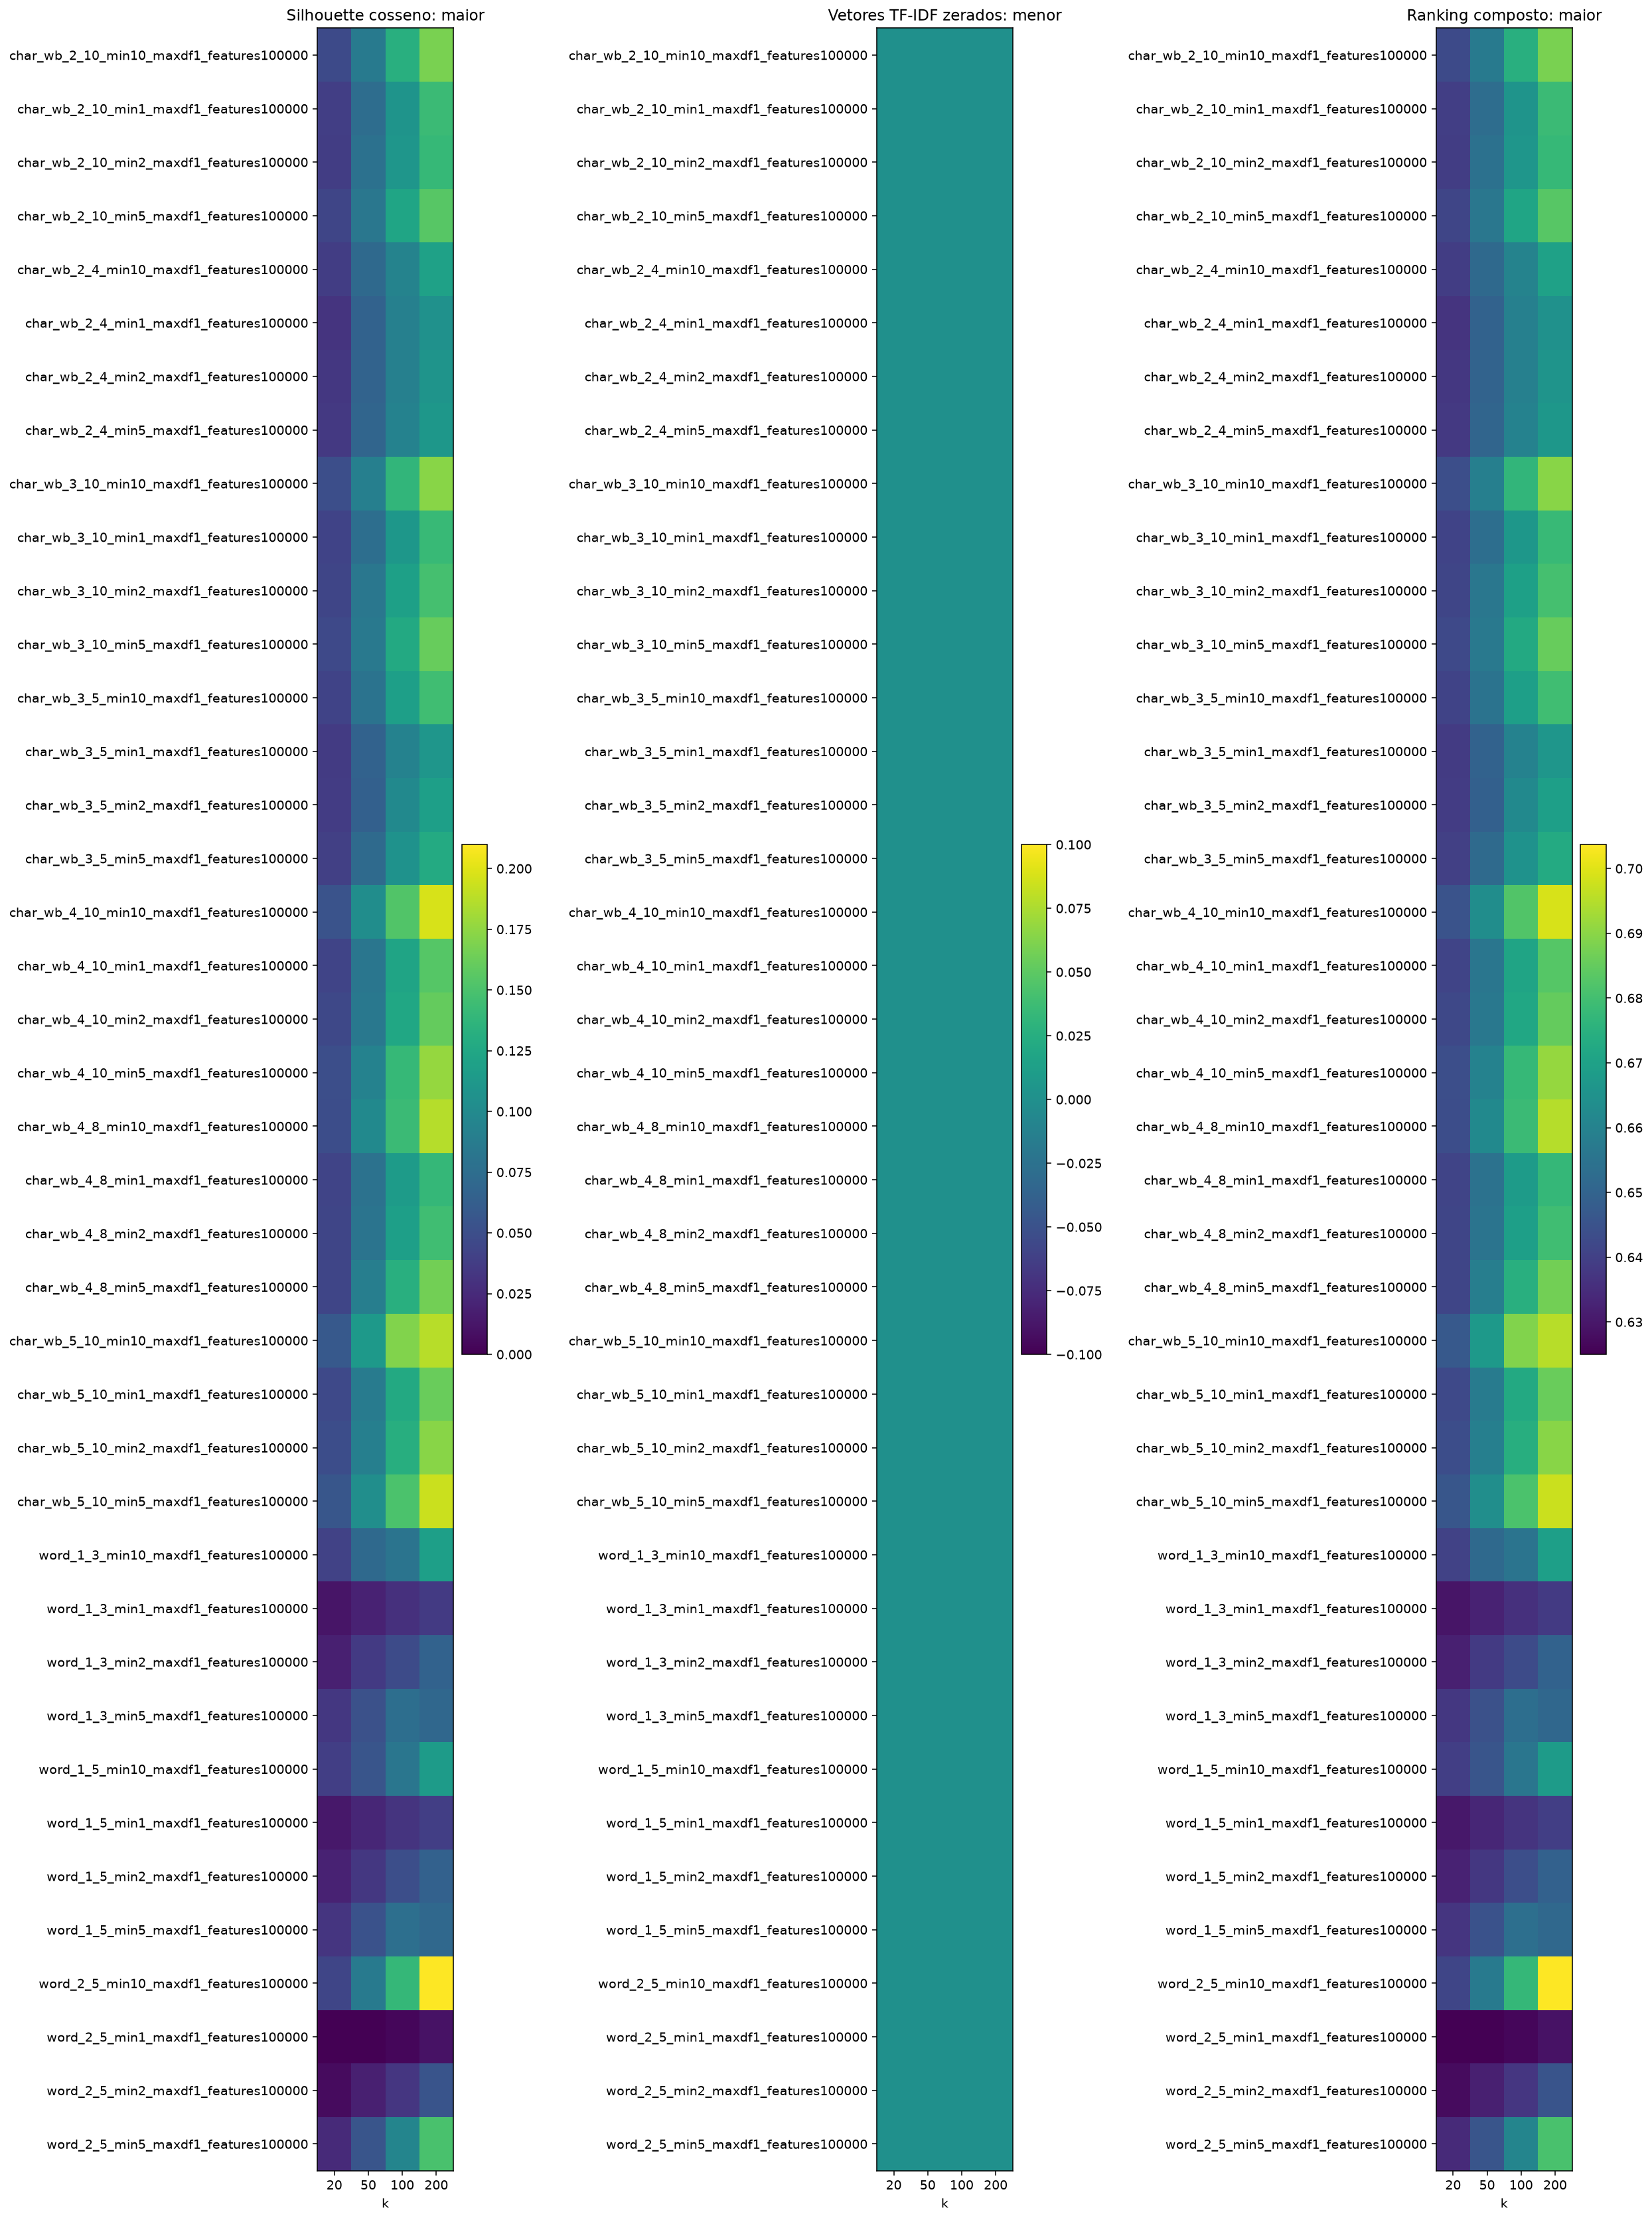

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, max(4, len(configs) * 0.6)))
for ax, metric, title in zip(
    axes,
    ["silhouette_median", "noise_fraction_median", "composite_score_median"],
    ["Silhouette cosseno: maior", "Vetores TF-IDF zerados: menor", "Ranking composto: maior"],
):
    table = ranking.pivot(index="config_name", columns="k", values=metric)
    plot = ax.imshow(np.ma.masked_invalid(table.to_numpy(dtype=float)), aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(table.columns)), table.columns)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.set_xlabel("k")
    ax.set_title(title)
    fig.colorbar(plot, ax=ax, shrink=0.7)
fig.tight_layout()
fig.savefig(REPORT_DIR / "ranking_metrics.png", dpi=140, bbox_inches="tight")
plt.show()


## 5. Entender dez vetores e revisar os clusters dos candidatos

Os mesmos dez produtos são inspecionados em cada representação candidata. Leia os termos com
maior peso e identifique se representam produto, marca ou embalagem. As funções compartilhadas
de inspeção e classificação ficam em `src/nofis_classifier/clustering.py`; treinamento, métricas e
ranking estão definidos neste notebook.

Cada candidato recebe `assignments.csv`, `documents_tfidf.csv` e **`cluster_review.csv`**.
Este último é editável: preencha `avaliacao_qualitativa` com `coerente`,
`parcialmente coerente` ou `heterogeneo`; preencha `rotulo_humano` e `observacoes`.
Comece pelos cinco maiores grupos, mas revise todos os grupos que pretende categorizar.
É permitido dar a mesma categoria a vários clusters. O número do cluster só vale naquele modelo.

Exemplos distantes são os mais afastados do centroide, não necessariamente os mais próximos
da fronteira com outro cluster. Compare-os com os exemplos centrais e aleatórios.
Os CSVs editáveis existentes **não são sobrescritos** quando a célula roda novamente.

In [10]:
# Etapa 1: preparar e salvar os materiais de revisao e graficos t-SNE dos candidatos.
tsne_by_vectorizer = {}
for row in candidates.itertuples(index=False):
    candidate_dir = REPORT_DIR / "review" / row.experiment_id
    vectorizer = load_local_model(row.vectorizer_path)
    model = load_local_model(row.model_path)

    # Separa dez descricoes para inspecionar como cada representacao as vetoriza.
    documents = inspect_documents(train, vectorizer, count=10, seed=SPLIT_SEED)

    # Associa cada descricao do treino a um cluster e resume os grupos para revisao humana.
    assignments, cluster_review = build_cluster_review(
        train, vectorizer, model, row.experiment_id
    )
    cluster_review_by_frequency = cluster_review.sort_values(
        "frequencia_total", ascending=False
    ).reset_index(drop=True)
    cluster_sizes = assignments.groupby("cluster")[DESCRIPTION_NORMALIZED].size()
    singleton_clusters = cluster_sizes[cluster_sizes.eq(1)].index
    frequent_singletons = assignments[assignments["cluster"].isin(singleton_clusters)].sort_values(
        FREQUENCY, ascending=False
    )

    # Cria os arquivos apenas se ainda nao existirem, preservando revisoes manuais anteriores.
    save_review_once(documents, candidate_dir / "documents_tfidf.csv")
    save_review_once(assignments, candidate_dir / "assignments.csv")
    save_review_once(cluster_review, candidate_dir / "cluster_review.csv")
    save_review_once(cluster_review_by_frequency, candidate_dir / "cluster_review_by_frequency.csv")
    save_review_once(frequent_singletons, candidate_dir / "frequent_singleton_descriptions.csv")

    if row.vectorizer_path not in tsne_by_vectorizer:
        features = vectorizer.transform(train[DESCRIPTION_NORMALIZED])
        projection_2d = compute_tsne_projection(features, TSNE_MAX_POINTS, TSNE_PERPLEXITY, TSNE_MAX_ITER, TSNE_RANDOM_STATE)
        projection_3d = compute_tsne_projection(features, TSNE_MAX_POINTS, TSNE_PERPLEXITY, TSNE_MAX_ITER, TSNE_RANDOM_STATE, n_components=TSNE_3D_N_COMPONENTS)
        tsne_by_vectorizer[row.vectorizer_path] = (projection_2d, projection_3d)
    (indices, coordinates, _), (indices_3d, coordinates_3d, _) = tsne_by_vectorizer[row.vectorizer_path]
    assert np.array_equal(indices, indices_3d)
    projection_frame = train.iloc[indices][[DESCRIPTION_NORMALIZED, FREQUENCY]].copy()
    projection_frame[["tsne_1", "tsne_2"]] = coordinates
    projection_frame[["tsne_3d_1", "tsne_3d_2", "tsne_3d_3"]] = coordinates_3d
    save_review_once(projection_frame, candidate_dir / "tsne_coordinates.csv")
    labels = assignments.iloc[indices]["cluster"].to_numpy()
    save_tsne_plot(coordinates, labels, row.experiment_id, candidate_dir / "tsne.png")
    save_tsne_3d_html(coordinates_3d, labels, row.experiment_id, candidate_dir / "tsne_3d.html")
    logger.info("Materiais de revisao e t-SNE 2D/3D salvos: %s", candidate_dir)


2026-10-24 18:14:34,081 INFO Materiais de revisao e t-SNE 2D/3D salvos: C:\Users\samuel.simao\Sources\Nofis-Classifier\reports\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\review\word_2_5_min10_maxdf1_features100000_k200_seed42


2026-10-24 18:15:17,725 INFO Materiais de revisao e t-SNE 2D/3D salvos: C:\Users\samuel.simao\Sources\Nofis-Classifier\reports\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\review\char_wb_4_10_min10_maxdf1_features100000_k200_seed42


2026-10-24 18:15:50,607 INFO Materiais de revisao e t-SNE 2D/3D salvos: C:\Users\samuel.simao\Sources\Nofis-Classifier\reports\tfidf_kmeans\202501-202512_20261024T183332Z_8ae789b8\review\char_wb_5_10_min5_maxdf1_features100000_k200_seed42


### O que foi salvo em cada pasta de candidato?

- `documents_tfidf.csv`: dez descricoes amostradas, seus termos TF-IDF de maior peso e indicacao de vetor zerado.
- `assignments.csv`: descricoes do treino e o cluster atribuido pelo modelo.
- `cluster_review.csv`: resumo dos clusters, com exemplos representativos para preencher a avaliacao e o rotulo humano.
- `tsne.png`: projecao t-SNE da amostra, colorida pelos clusters K-Means do candidato.

A celula seguinte apenas le os arquivos e mostra uma amostra na tela. Ela nao altera os CSVs.


In [11]:
# Etapa 2: mostrar os materiais com uma explicacao antes de cada tabela.
for row in candidates.itertuples(index=False):
    candidate_dir = REPORT_DIR / "review" / row.experiment_id
    print(f"\nCandidato: {row.experiment_id}")

    documents = pd.read_csv(candidate_dir / "documents_tfidf.csv")
    cluster_review = pd.read_csv(candidate_dir / "cluster_review.csv")

    print("Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.")
    display(documents[[DESCRIPTION_NORMALIZED, "termos_tfidf", "sem_vocabulario"]])

    print("Resumo dos clusters: primeiros cinco grupos, com descricoes representativas e campos para orientar a revisao humana. O arquivo completo pode ser editado em cluster_review.csv.")
    display(cluster_review.head(5))



Candidato: word_2_5_min10_maxdf1_features100000_k200_seed42
Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.


,descricao_normalizada,termos_tfidf,sem_vocabulario
0,jogo xicaras cha vdr cristal 6pcs 165ml,NaN,True
1,at esp pl 152 2,NaN,True
2,fita adesiva acrilico alta resistencia dupla face 24mm x 2 m cap 5 kgs,fita adesiva: 0.780 | dupla face: 0.626,False
3,agua sanitaria asa leste super forte 5l,agua sanitaria: 1.000,False
4,pao artesanal pao caseiro doce,NaN,True
5,macarrao tipo lasanha 500g,macarrao tipo: 1.000,False
6,limpa acd granada 200ml 12,NaN,True
7,biofor 1000ml desinfetante composicao base iodoformio,NaN,True
8,vela cilindro 2,NaN,True
9,far trigo d benta cfer 1kg,far trigo: 1.000,False


Resumo dos clusters: primeiros cinco grupos, com descricoes representativas e campos para orientar a revisao humana. O arquivo completo pode ser editado em cluster_review.csv.


,experiment_id,cluster,termos_relevantes,exemplos_centrais,exemplos_distantes,exemplos_aleatorios,descricoes_unicas,frequencia_total,sem_vocabulario,avaliacao_qualitativa,rotulo_humano,observacoes
0,word_2_5_min10_maxdf1_features100000_k200_seed42,0,original line | 100 und | dr oetker | pacote com | milho pipoca | suco concentrado | pct 100 | com 100 | colher mesa | ervilha conserva | sabao po | acucar ...,zlav 06 alvejante peroxidado liquido bb50l marca eximia lt l f 02 25 v 02 26 | zinfos nucleo ovino 4 vmp 20kg | yakissoba | xylitol kodilar 300g | xtapa fr ...,sal master refinado iodado 01kg | desinfetante composicao base quaternario amonio caract adicionais com aroma principio ativo cloreto alquil dim | uzu etili...,fuba milho fino embalagem com 1kg | carne bovina conserva | carvao pacote | p hig paloma folha simples 4pcx16rlx30m | cominho moido esse bao 20g 1028 | maca...,13885,72242,10796,REVISAR,NaN,NaN
1,word_2_5_min10_maxdf1_features100000_k200_seed42,2,saco lixo | lixo 50l | lixo 60 | lixo 30l | lixo 200l | pct 100 | azul 100 | lixo plastico | 20 lt | 100 unidades | lixo 50 | 30 litros | 10 und | 10 un | l...,saco lixo 100lt | saco lixo 100lt infectante branco n | saco lixo 100lt preto 0 2 health clean | saco lixo 150l preto c 50 | saco lixo 15l azul rolo c 100 f...,saco lixo 50 lts pct c 100 unds | saco p lixo 50l preto pct c 100 health clean | saco lixo plastico preto 100l 0 05mm pt 100un | saco lixo plastico cap 50 l...,saco lixo 100lt | saco lixo rava preto 60l | saco lixo 50l infectante leitoso | saco p lixo brizzi 30l rolo | saco lixo embalixo pto s econ 30l c 50 | saco ...,175,928,0,REVISAR,NaN,NaN
2,word_2_5_min10_maxdf1_features100000_k200_seed42,15,papel toalha | 100 celulose | toalha interf | 1000 folhas | celulose virgem | cor branco | 20 cm,dispenser papel toalha dispenser para papel toalha interfolhada produzido plastico ps alto impacto com baixa d | dispenser papel toalha inox | fardo 6 bobin...,papel toalha interf bco celulose virgem pct c 1 000 fls belapell | papel toalha 100 celulose 1000 folhas | papel toalha 100 celulose jarau 20 x 21 1000 folh...,papel toalha inter branco c 1000 ms papeis | papel toalha interfolhado 2d fs celulose pcts c 1000 folhas marca nc papeis | papel toalha scala plus 360fls | ...,114,727,0,REVISAR,NaN,NaN
3,word_2_5_min10_maxdf1_features100000_k200_seed42,10,agua mineral | mineral natural | agua mineral natural | 20 litros | sem gas | com gas | mineral 20 | agua mineral 20 | gas 500ml | natural sem | 20 lts | ti...,agua mineral 1 500ml hidratar | agua mineral 20l retornavel floratta | agua mineral 20l cristal sul | agua mineral 20lts retornavel | agua mineral 20lts ter...,agua mineral natural tipo especial 700 00 com gas | agua mineral tipo 2 sem gas 500ml | agua mineral tipo sem gas | agua mineral tipo 1 sem gas | agua miner...,agua mineral 500ml vitta s gas | agua mineral natural 20l retornavel | agua mineral 1 500ml hidratar | envase agua mineral 20 litros | agua mineral natural ...,111,1234,0,REVISAR,NaN,NaN
4,word_2_5_min10_maxdf1_features100000_k200_seed42,20,papel hig | fl dupla | 100 celulose | folha simples | pacote com,canoinhas papel hig fofinho f simples neutro c 12 30 m | dispenser papel hig rolo bellplus | papel hig 10x30m velud f dupla rolo | papel hig 2 6 c 08 rl 100...,papel hig rolinho 100 celulose fl dupla pct 16x30m velud | papel hig rolinho 100 celulose fl dupla pct 4x30m ouroppel | papel hig rolinho 100 celulose fl du...,papel hig mili fd 30m c 16 neutro | papel hig velud l12 p11 | papel hig rolao 100 cel 9x300 mts c 8 avantebrasil | papel hig duetto fit 30m 32rolos | papel ...,94,420,0,REVISAR,NaN,NaN



Candidato: char_wb_4_10_min10_maxdf1_features100000_k200_seed42
Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.


...

,experiment_id,cluster,termos_relevantes,exemplos_centrais,exemplos_distantes,exemplos_aleatorios,descricoes_unicas,frequencia_total,sem_vocabulario,avaliacao_qualitativa,rotulo_humano,observacoes
0,char_wb_4_10_min10_maxdf1_features100000_k200_seed42,85,1 | c | kg | 0ml | 00g | 500 | 00ml | 00ml | con | nte | 100 | des | cao | ado | 2,taioba | burit | ks | ripa | vodka smirnoff 998ml | ihb0317,yakissoba | input | 3m muffler hb | ci 5m 02659r | optiloop gota | xampu aussie,fr 1000 lata aco 1 l onu 1993 liquido inflamavel n nafta isopropanol 3 ii | pano chao mega panao azul 80x90cm | seq 028 forro mesa | pe moleque c 50 | lubri...,3958,18377,6,REVISAR,NaN,NaN
1,char_wb_4_10_min10_maxdf1_features100000_k200_seed42,19,rtav | cartav | artav | descarta | scartav | escarta | scarta | escartav | descartav | rtave | cartave | descartave | scartave | escartave | artave,copo descartavel cx | copo descartavel 50 ml | copo descartavel 100 ml | zz jaleco descartavel | copo descartavel 200 ml | luva descartavel c 100 un,copos descartaveis 200ml biodegradavel | talher descartaval tipo mexedor | fralda descartavel infantil tamanho grande material higienico atoxico com formato...,copo descartavel 300ml pct 100x1 | colher descartavel refeicao bello festas 50 unidades | touca nao esteril descartavel com elastico pacote com 100 und | co...,260,1842,0,REVISAR,NaN,NaN
2,char_wb_4_10_min10_maxdf1_features100000_k200_seed42,8,saco | saco | saco | saco | lixo | lixo | ixo | sac | lixo | lixo | aco | lix | 100 | c | 00l,saco lixo 20 lt c 100 | saco lixo 60 l c 100 | saco lixo 360lt | saco lixo lixo 20l | saco lixo 100 l c 05 un | saco lixo 30 lts,saco ultra ls pe vac 22x32x15 tr c 100un | sc p lixo reforcado uai 50l | saco para lixo up bag green oxibiodegradavel verde 50l 50un | saco cru 50x78 pano s...,saco lixo dobrasil rol az 30l 20x1 | saco 40x60 | sacos p lixo eco forte 30l c 10und | saco c 10 | saco pe 8x13 | saco lixo infectante 100l 1x1,242,1348,0,REVISAR,NaN,NaN
3,char_wb_4_10_min10_maxdf1_features100000_k200_seed42,98,plastico | plastico | plastico | plastico | lastico | astico | astico | lastico | stico | stico | tico | tico | plastic | plastic | plasti,plastico | saco plastico | cabide plastico | saco plastico kg | saco plastico 3 kg | saco plastico 16cm,ferramenta plastico utilizada durante teste ignicao sistema para turbina apu | elastico ortodontico tipo p ligadura | paliteiro mat plastico formato cilindr...,cavalete plastico | stencil plastico pintura 14cm x 14cm | saco plastico pe 60x90x0 06 c 100 | regador plastico tipo bico chuveiro 10 litros | caixa arquivo...,226,779,0,REVISAR,NaN,NaN
4,char_wb_4_10_min10_maxdf1_features100000_k200_seed42,55,chocola | hocola | ocola | chocol | hocol | ocol | olat | hocolat | colat | chocolat | ocolat | hoco | choco | chocola | chocol,chocolate po 2 kg | cupcake chocolate | muffins chocolate | trufa chocolate conhac | chocolate po 500g | chocolate po 50 c 200 g,achocolatado 400gr pacote la rend un | achocolatado po marata sache 400g | achocolatado po especiali 400g | achocolatado liq toddynho trad tp 200ml 27 | ach...,barra cereais chocolate 25g | biscoito waffer chocolate 140gr | biscoito mini waffer chocolate | chocolate branco nobre procedencia brasil | panettone panco...,193,984,0,REVISAR,NaN,NaN



Candidato: char_wb_5_10_min5_maxdf1_features100000_k200_seed42
Amostra de descricoes: dez itens do treino e seus termos TF-IDF de maior peso. A coluna sem_vocabulario indica se o item ficou sem termos conhecidos pelo vetorizar.


,descricao_normalizada,termos_tfidf,sem_vocabulario
0,jogo xicaras cha vdr cristal 6pcs 165ml,65ml : 0.239 | caras : 0.231 | aras : 0.228 | caras: 0.228 | xicar: 0.226 | xicara: 0.226 | xica: 0.226 | xicar: 0.223 | xicara: 0.223 | icara: 0.217,False
1,at esp pl 152 2,pl : 0.705 | esp : 0.604 | 2 : 0.371,False
2,fita adesiva acrilico alta resistencia dupla face 24mm x 2 m cap 5 kgs,resistenci: 0.127 | resistenc: 0.127 | esistencia: 0.127 | resistenc: 0.127 | esistenc: 0.127 | esistenci: 0.127 | stencia : 0.125 | istencia : 0.125 | ist...,False
3,agua sanitaria asa leste super forte 5l,asa : 0.207 | leste : 0.204 | leste: 0.201 | este : 0.178 | forte : 0.169 | forte: 0.166 | forte : 0.166 | super : 0.165 | uper : 0.164 | super : 0.164,False
4,pao artesanal pao caseiro doce,pao : 0.173 | tesanal : 0.160 | rtesanal: 0.160 | rtesanal : 0.160 | sanal: 0.160 | tesanal: 0.160 | esanal : 0.160 | artesanal: 0.160 | esanal: 0.160 | a...,False
5,macarrao tipo lasanha 500g,sanha : 0.176 | sanha: 0.176 | lasanha : 0.176 | lasanh: 0.176 | asanh: 0.176 | asanha : 0.176 | asanha: 0.176 | lasan: 0.176 | lasanh: 0.176 | lasanha: 0.176,False
6,limpa acd granada 200ml 12,ranada : 0.231 | ranada: 0.231 | granada: 0.231 | granada : 0.231 | granada: 0.231 | granada : 0.231 | granad: 0.224 | ranad: 0.224 | grana: 0.224 | gra...,False
7,biofor 1000ml desinfetante composicao base iodoformio,biof: 0.152 | formi: 0.144 | oform: 0.136 | 1000ml : 0.116 | 1000ml: 0.116 | 1000ml : 0.115 | 1000ml: 0.114 | 1000m: 0.114 | 000ml : 0.113 | 000ml: 0.113,False
8,vela cilindro 2,ndro : 0.217 | ilindro : 0.217 | lindro : 0.217 | lindro: 0.217 | indro : 0.217 | ilindro: 0.217 | indro: 0.217 | cilindro : 0.217 | cilindro: 0.217 | cili...,False
9,far trigo d benta cfer 1kg,benta : 0.313 | benta: 0.313 | benta: 0.313 | benta : 0.313 | bent: 0.310 | far : 0.280 | enta : 0.241 | d : 0.235 | trigo : 0.221 | trigo : 0.221,False


Resumo dos clusters: primeiros cinco grupos, com descricoes representativas e campos para orientar a revisao humana. O arquivo completo pode ser editado em cluster_review.csv.


,experiment_id,cluster,termos_relevantes,exemplos_centrais,exemplos_distantes,exemplos_aleatorios,descricoes_unicas,frequencia_total,sem_vocabulario,avaliacao_qualitativa,rotulo_humano,observacoes
0,char_wb_5_10_min5_maxdf1_features100000_k200_seed42,7,c | kg | 1 | pao | para | po | 00ml | ador | para | p | para | 5 | 500g | x | 500g,yakissoba | pallet | ripa | taioba | chokito 32g | obreias,bergamota | burit | bregeres codorna | amora | str 200l 8190 1494j | xerox versalink c7030,presilha fixacao pro | luva p proced nitrilo tam pequeno | farofa picante | luz placa | aptamil pre 1 400 g pro expert danone medical | germi rio pronto uso...,4597,24799,22,REVISAR,NaN,NaN
1,char_wb_5_10_min5_maxdf1_features100000_k200_seed42,44,pape | apel | papel | papel | papel | papel | toalha | oalha | toal | toalh | toalha | toalh | oalha | toalha | toalha,toalha papel 2 rlo | papel toalha fd pct 02rl | papel toalha yuri 2un | papel toalha pct c 2 und | papel toalha 100 cel | papel toalha snob 2x50fl,papel art crepe artfl sortido | papel hig qualite campione 10cmx30m 28g 4 rls | papel hig sublime f dupla l12p11 | papel hig premium 8x300m 5 unica | papel ...,papel toalha cozinha sirius pct c 2 rolos | toalha papel benn bco 20x21 1000f | papel bobina fd com 6 | dispenser papel toalha inox | papel toalha duas dobr...,336,1624,0,REVISAR,NaN,NaN
2,char_wb_5_10_min5_maxdf1_features100000_k200_seed42,160,plastico | plastico | plastico | plastico | astico | lastico | astico | lastico | stico | stico | tico | plastic | plastic | plasti | plasti,cabide plastico | plastico | saco plastico | saco plastico kg | saco plastico 5kg | saco plastico lixo 300l,potes plasticos sanremo 3un sr125 3c55 | desempenadeira manual plastico | saco plastico freezer microondas 30x40 5l rl c 100 orleplast | copo plastico desc ...,saco plastico vacuo nylon poli 18x25x0 16 cm 6 72 | pa para lixo c cabo 80 90 cm plastico | saco plastico lixo 50 litros cor preta | jarra plastico 3 lts | ...,253,955,0,REVISAR,NaN,NaN
3,char_wb_5_10_min5_maxdf1_features100000_k200_seed42,187,cartav | descartav | escarta | escartav | scartav | scarta | artav | descarta | cartave | descartave | rtave | artave | escartave | scartave | descartav,zz jaleco descartavel | copo descartavel cx | copo descartavel 100 ml | copo descartavel 50 ml | copo descartavel 200 ml | luva descartavel c 100 un,fralda descartavel tipo formato anatomico tamanho medio aproximadamente com barreira anti vazamento material man ab | fralda descartavel tipo fixacao tmh in...,colher descartavel p refeicao caixa c 50 unid s gnh 90089 2025 | pote descartavel biodegradavel branco psai capacidade 170 ml unitario | embalagem descartav...,240,1779,0,REVISAR,NaN,NaN
4,char_wb_5_10_min5_maxdf1_features100000_k200_seed42,70,saco | lixo | saco | saco | lixo | lixo | c | 100 | 30l | p | azul | azul | 50l | azul | 100l,saco lixo 360lt | saco lixo lixo 20l | saco lixo 20 lt c 100 | saco lixo 30 lts | saco lixo 60 l c 100 | saco para lixo 50l,saco pano chao vale | saco bb 50x90 0 0200 f c 10und | saco ultra ls pe vac 22x32x15 tr c 100un | saco 40x60 | cesto lixo plast 50 lts c tampa | saco lixo 5...,saco lixo azul 40 l | saco vir 80x120x0 20 kg | saco lixo rolo fix lixo 105l 15un | saco para lixo 50l | saco lixo pro casa rol 15l azul | saco lixo 100l az...,239,1332,0,REVISAR,NaN,NaN


In [12]:
# Troque o identificador e o cluster para explorar qualquer candidato preparado.
INSPECT_EXPERIMENT_ID = candidate_ids[0]
inspection_dir = REPORT_DIR / "review" / INSPECT_EXPERIMENT_ID
review = pd.read_csv(inspection_dir / "cluster_review.csv").fillna("")
assignments = pd.read_csv(inspection_dir / "assignments.csv")
CLUSTER_ID = int(review.iloc[0]["cluster"])
display(review.loc[review.cluster.eq(CLUSTER_ID)].T)
cluster_items = assignments[assignments.cluster.eq(CLUSTER_ID)]
display(cluster_items.sort_values("distancia_centroide").head(15))
display(cluster_items.sort_values("distancia_centroide", ascending=False).head(15))
display(cluster_items.sample(min(15, len(cluster_items)), random_state=42))

,0
experiment_id,word_2_5_min10_maxdf1_features100000_k200_seed42
cluster,0
termos_relevantes,original line | 100 und | dr oetker | pacote com | milho pipoca | suco concentrado | pct 100 | com 100 | colher mesa | ervilha conserva | sabao po | acucar ...
exemplos_centrais,zlav 06 alvejante peroxidado liquido bb50l marca eximia lt l f 02 25 v 02 26 | zinfos nucleo ovino 4 vmp 20kg | yakissoba | xylitol kodilar 300g | xtapa fr ...
exemplos_distantes,sal master refinado iodado 01kg | desinfetante composicao base quaternario amonio caract adicionais com aroma principio ativo cloreto alquil dim | uzu etili...
exemplos_aleatorios,fuba milho fino embalagem com 1kg | carne bovina conserva | carvao pacote | p hig paloma folha simples 4pcx16rlx30m | cominho moido esse bao 20g 1028 | maca...
descricoes_unicas,13885
frequencia_total,72242
sem_vocabulario,10796
avaliacao_qualitativa,REVISAR


,descricao_id,descricao_normalizada,frequencia,cluster,sem_vocabulario,distancia_centroide
19997,146980,zlav 06 alvejante peroxidado liquido bb50l marca eximia lt l f 02 25 v 02 26,1,0,True,0.013517
19996,146974,zinfos nucleo ovino 4 vmp 20kg,1,0,True,0.013517
19993,146922,yakissoba,2,0,True,0.013517
19992,146920,xylitol kodilar 300g,2,0,True,0.013517
19991,146917,xtapa fr citricas 450ml,1,0,True,0.013517
19990,146907,xicaras medidoras 4 pecas asa1501,5,0,True,0.013517
19989,146904,xicara vidro para cafe com pires,1,0,True,0.013517
19988,146900,xicara porcelana preta,2,0,True,0.013517
19987,146895,xicara porcelana,2,0,True,0.013517
16838,124421,rzolve limpa pisos 5 lt,1,0,True,0.013517


,descricao_id,descricao_normalizada,frequencia,cluster,sem_vocabulario,distancia_centroide
17835,131471,sal master refinado iodado 01kg,1,0,False,1.000019
6780,50948,desinfetante composicao base quaternario amonio caract adicionais com aroma principio ativo cloreto alquil dim,2,0,False,1.000019
19611,144219,uzu etilico hidratado liquido 70 1 lt,2,0,False,1.000019
214,1571,abracadeira 140x3 6 140x3 5 150x3 6 preta 100 pcs ap1435 12113 mb rayco ehc 11540 42,1,0,False,1.000019
19006,139824,tampa aptus radius 2 5 para 6020 6026 lote r07v13 anvisa isento,1,0,False,1.000019
1449,11293,algemas descartaveis nylon preta dupla,1,0,False,1.000019
11576,85961,luva lalan latex multiuso amarela p ca39564,1,0,False,1.000019
11658,86630,luva mulituso nitrilica sem forro antiderrapante 45cm verde tamanho g,1,0,False,1.000019
7789,58419,espon aco assolan c 8 45g,2,0,False,0.999967
11727,87234,luva proced vinil s po tam m,5,0,False,0.999967


,descricao_id,descricao_normalizada,frequencia,cluster,sem_vocabulario,distancia_centroide
9197,68441,fuba milho fino embalagem com 1kg,2,0,False,0.998964
4747,35735,carne bovina conserva,1,0,False,0.999515
4802,36162,carvao pacote,10,0,True,0.013517
13488,100168,p hig paloma folha simples 4pcx16rlx30m,1,0,False,0.999635
5835,43874,cominho moido esse bao 20g 1028,1,0,True,0.013517
11940,88745,macarrao penne c ovos 500gr,1,0,True,0.013517
10541,78274,jantar categoria 5 estudantes graduacao presencial sem piso,8,0,True,0.013517
9711,72153,golden special adulto 20 kg,2,0,False,0.999032
2280,17642,bacon defumado 1 dn 90075 2025,4,0,True,0.013517
10436,77469,item 72,9,0,True,0.013517


## 6. Escolha humana, taxonomia e validação reservada

Depois de revisar os candidatos, copie o `experiment_id` escolhido abaixo e justifique a escolha.
A escolha não acontece automaticamente ao executar tudo. Só grupos marcados **coerente** e
com rótulo preenchido serão categorizados; os demais retornam `REVISAR`. Isso permite começar
com cobertura parcial. Mesmo um cluster coerente pode receber um item novo inadequado;
este protótipo não implementa rejeição por distância nem estima confiança.

Com a taxonomia escolhida, a próxima célula cria `validation_labels.csv`, sem mostrar predições.
Preencha `categoria_esperada` manualmente usando as categorias definidas, antes de abrir os
resultados do modelo. Use `FORA_DA_TAXONOMIA` para itens fora do escopo das categorias;
`REVISAR` é reservado à abstenção do modelo. Células vazias não são avaliadas.
Não mude a taxonomia olhando os erros dessa reserva e depois a apresente como teste independente.
Se precisar refiná-la, transforme esta reserva em desenvolvimento e separe um novo teste.

In [13]:
SELECTED_EXPERIMENT_ID = None  # Cole aqui um experiment_id que você revisou.
SELECTION_REASON = ""  # Explique a escolha com métricas e exemplos dos clusters.

In [14]:
selected_ready = False
if SELECTED_EXPERIMENT_ID is None:
    logger.info("Etapa automática concluída. Revise os CSVs e escolha um experimento na célula anterior.")
else:
    if not SELECTION_REASON.strip():
        raise ValueError("Registre a justificativa da escolha em SELECTION_REASON.")
    selected_rows = metrics[metrics.experiment_id.eq(SELECTED_EXPERIMENT_ID) & metrics.status.eq("ok")]
    if len(selected_rows) != 1:
        raise ValueError("Escolha um experimento concluído desta execução.")
    selected = selected_rows.iloc[0]
    selected_dir = REPORT_DIR / "review" / SELECTED_EXPERIMENT_ID
    review_path = selected_dir / "cluster_review.csv"
    if not review_path.exists():
        raise ValueError("Prepare a revisão desse experimento na seção 5 antes de selecioná-lo.")
    selected_review = pd.read_csv(review_path).fillna("")
    accepted = selected_review[
        selected_review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente")
        & selected_review.rotulo_humano.str.strip().ne("")
    ]
    if accepted.empty:
        logger.info("Preencha os rótulos e marque os clusters coerentes antes de validar.")
    else:
        selected_vectorizer = load_local_model(selected.vectorizer_path)
        selected_model = load_local_model(selected.model_path)
        validation_path = selected_dir / "validation_labels.csv"
        template = validation[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].copy()
        template["categoria_esperada"] = ""
        template["observacoes"] = ""
        save_review_once(template, validation_path)
        selected_ready = True
        display(accepted[["cluster", "rotulo_humano", "descricoes_unicas", "frequencia_total"]])
        logger.info("Preencha os rótulos independentes em %s", validation_path)

2026-10-24 18:15:50,807 INFO Etapa automática concluída. Revise os CSVs e escolha um experimento na célula anterior.


## 7. Avaliar a classificação e experimentar novas descrições

A avaliação informa cobertura (fração que recebeu categoria), acurácia incluindo abstenções
como erros, acurácia apenas nos itens categorizados, relatório por categoria e matriz de confusão.
As métricas são por descrição única, sem ponderação por frequência. Uma avaliação parcial
é identificada como tal; conclua os rótulos antes de apresentar o resultado final.

Cada avaliação gera uma pasta nova, preservando o mapa de categorias, a justificativa e os
rótulos utilizados. TF-IDF e K-Means são os já ajustados: aqui usamos apenas `transform` e
`predict`. Textos sem vocabulário conhecido retornam `REVISAR`.

In [15]:
if selected_ready:
    # Releitura permite editar os CSVs e repetir somente esta célula.
    selected_review = pd.read_csv(review_path).fillna("")
    human_labels = pd.read_csv(validation_path).fillna("")
    if human_labels.descricao_id.duplicated().any():
        raise ValueError("Há IDs duplicados na validação.")
    expected = validation.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    actual = human_labels.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    if not expected.index.equals(actual.index) or expected.tolist() != actual.tolist():
        raise ValueError("Não altere IDs ou descrições da reserva; preencha apenas os rótulos e observações.")
    human_labels["categoria_esperada"] = human_labels["categoria_esperada"].str.strip()
    labeled = human_labels[human_labels.categoria_esperada.ne("")].copy()
    if labeled.empty:
        logger.info("Validação pendente: preencha categoria_esperada e execute novamente esta célula.")
    else:
        allowed = set(selected_review.loc[
            selected_review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente"),
            "rotulo_humano",
        ].str.strip()) - {"", "REVISAR"}
        if not set(labeled.categoria_esperada).issubset(allowed | {"FORA_DA_TAXONOMIA"}):
            raise ValueError("Use as categorias revisadas ou FORA_DA_TAXONOMIA nos rótulos esperados.")
        predictions = predict_categories(labeled[DESCRIPTION_NORMALIZED], selected_vectorizer,
                                          selected_model, selected_review, SELECTED_EXPERIMENT_ID)
        evaluated = labeled.reset_index(drop=True).assign(
            categoria_predita=predictions.categoria.to_numpy(), cluster=predictions.cluster.to_numpy(),
        )
        y_true, y_pred = evaluated.categoria_esperada, evaluated.categoria_predita
        covered = y_pred.ne("REVISAR")
        summary = pd.DataFrame([{
            "experiment_id": SELECTED_EXPERIMENT_ID, "reserva_total": len(validation),
            "rotulados": len(evaluated), "avaliacao_completa": len(evaluated) == len(validation),
            "cobertura": float(covered.mean()),
            "acuracia_incluindo_abstencoes": accuracy_score(y_true, y_pred),
            "acuracia_itens_categorizados": accuracy_score(y_true[covered], y_pred[covered]) if covered.any() else np.nan,
        }])
        labels = sorted(set(y_true) | set(y_pred))
        confusion = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels),
                                 index=pd.Index(labels, name="esperada"), columns=labels)
        per_class = pd.DataFrame(classification_report(y_true, y_pred, output_dict=True, zero_division=0)).T
        evaluation_dir = selected_dir / ("evaluation_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8])
        evaluation_dir.mkdir()
        summary.to_csv(evaluation_dir / "summary.csv", index=False)
        evaluated.to_csv(evaluation_dir / "predictions.csv", index=False)
        confusion.to_csv(evaluation_dir / "confusion_matrix.csv")
        per_class.to_csv(evaluation_dir / "classification_report.csv")
        selected_review.to_csv(evaluation_dir / "taxonomy_snapshot.csv", index=False)
        (evaluation_dir / "decision.json").write_text(json.dumps({
            "experiment_id": SELECTED_EXPERIMENT_ID, "reason": SELECTION_REASON,
            "model_path": selected.model_path, "vectorizer_path": selected.vectorizer_path,
        }, indent=2, ensure_ascii=False), encoding="utf-8")
        display(summary)
        display(confusion)
        display(per_class)
        display(evaluated.loc[y_true.ne(y_pred)].head(20))
else:
    logger.info("Avaliação aguardando escolha humana e taxonomia revisada.")

2026-10-24 18:15:50,839 INFO Avaliação aguardando escolha humana e taxonomia revisada.


In [16]:
NEW_DESCRIPTIONS = ["LEITE INTEGRAL 1L", "DETERGENTE NEUTRO 500ML", "xyzdesconhecido"]
if selected_ready:
    display(predict_categories(
        NEW_DESCRIPTIONS, selected_vectorizer, selected_model,
        pd.read_csv(review_path).fillna(""), SELECTED_EXPERIMENT_ID,
    ))

## Registro para o TCC

Registre a base e a reserva utilizadas, parâmetros, resultados entre sementes, clusters
coerentes e heterogêneos, justificativa da taxonomia, cobertura, erros e limitações.
O ranking seleciona candidatos; a avaliação humana verifica se os grupos servem às categorias.
Não compare números de clusters entre modelos como se identificassem a mesma categoria.

Artefatos: `planned_grid.csv`, `run.json`, `metrics.csv`, `ranking.csv`, gráficos,
`candidates.csv`, subpastas `review/` e os modelos da execução em `models/tfidf_kmeans/`.
Os arquivos pickle devem ser carregados somente quando produzidos e confiados localmente.

Referências oficiais:
- [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [Agrupamento de textos](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html)